# Three-day NOAA-20 active-fire detection forecast for central Spain

Each forecast is issued at **00:00 UTC** for a **0.25° × 0.25°** cell on the existing 16 × 18 grid. The notebook fits three **CatBoost** classifiers. All three scores use inputs available at the same issue time.

| Output | UTC interval for an issue on July 15 | Positive label |
|---|---|---|
| `p_day1` | July 15 00:00 to July 16 00:00 | At least one NOAA-20 FIRMS detection during July 15 |
| `p_day2` | July 16 00:00 to July 17 00:00 | At least one NOAA-20 FIRMS detection during July 16 |
| `p_day3` | July 17 00:00 to July 18 00:00 | At least one NOAA-20 FIRMS detection during July 17 |

Every interval includes its start and excludes its end. The previous NOAA-20 experiment's target rule applies to all three days. It uses any NOAA-20 detection from the verified `VIIRS_NOAA20_SP` or `VIIRS_NOAA20_NRT` interval. The scores estimate the probability of a recorded detection. Overpass timing, clouds and detection sensitivity affect the labels.

Training is eligible from **1 January 2018**. The attached experiment's saved output shows **1 April 2018** as its first verified NOAA-20 day. This notebook derives actual coverage from the report on Drive. It keeps earlier environmental rows for the original input tables and trailing windows. Validation starts on 1 July 2024 and the test period is 2025.

The inputs include all environmental, geographic, seasonal and environmental temporal predictors from the original notebook. FIRMS is used only to build labels. The feature matrix contains no active-fire counts, FRP, neighbor detections, time since detection or fire-catalogue coverage flags from any platform.

**Run in Google Colab.** Connect Google Drive, check `DRIVE_ROOT` in the first code cell and run the cells in order. The existing input folder contains `detections/detections_spain.parquet`, `detections/firms_coverage_by_year.csv` and the prepared tables under `features/`.

## Historical availability and missing values

| Input | Eligibility and treatment of gaps |
|---|---|
| **NOAA-20 target** | A verified UTC day with no NOAA-20 detections in a cell receives `0`. A recorded detection gives `1`. Days without verified catalogue coverage and verification days beyond the archive stay unlabeled. |
| **GFS weather, Day 1** | First eligible issue in the prepared product is 2 Jul 2015. Use maximum temperature, minimum relative humidity, maximum wind speed, and precipitation total from the previous day's 18:00 UTC cycle. Unavailable fields stay `NaN`. |
| **GFS weather, Days 2 and 3** | The prepared extended horizons begin on 10 Jul 2017. Both use the same 18:00 UTC cycle as Day 1. A model uses Day 1 weather through its own forecast day. Earlier dates and gaps stay `NaN`. |
| **NASADEM elevation and slope** | Use the same terrain for all years. Missing terrain cells stay `NaN`. |
| **CORINE land cover** | Use CORINE 2012 from the 19 Sep 2016 release date and CORINE 2018 from its 14 Jun 2019 publication date. Fraction columns stay `NaN` before the first eligible downloaded snapshot. These cutovers use the historical map releases as a proxy for availability of the reprocessed layers on Drive. Within an eligible snapshot, missing cells stay `NaN`. [2012 release lineage](https://doi.org/10.2909/7c96ac5d-399e-4151-a780-1f974fd75123) · [2018 publication](https://www.eea.europa.eu/en/datahub/datahubitem-view/a5144888-ee2a-4e5d-a7b0-2bbf21656348) |
| **SMAP surface soil moisture** | Observations start on 31 Mar 2015. The prepared lag allows a daily value from 8 Apr 2015 at the earliest, and a complete trailing seven-day mean from 14 Apr 2015 at the earliest. Keep the two columns and their gaps as prepared. |
| **MODIS Terra NDMI** | Use the prepared vegetation moisture proxy throughout the study period. The preparation uses an eight-day composite, a three-day release buffer, at least 20% valid pixels and up to 24 days of past-only fallback after assumed release. Gaps stay `NaN`. |
| **Fire Weather Index (FWI)** | The prepared GFS-based Day 1 FWI follows a 120-day warm-up, with 30 Oct 2015 as its earliest eligible issue. Use it as issue-day context for all three models. Gaps stay `NaN`. |
| **Location and season** | Derive cell centers and cyclic day-of-year features for every issue. |


Each horizon uses location, season, terrain, land cover, SMAP, Terra NDMI and FWI. It uses GFS forecasts through its own verification day, prior weather and FWI summaries, SMAP and NDMI changes, and observation age when the corresponding prepared export carries the source dates. Days 2 and 3 also include cumulative forecast precipitation through their own day.

CatBoost handles numeric `NaN` values directly. Environmental inputs follow the source preparation lags and the GFS forecast cycle described above.

In [1]:
from functools import lru_cache
from hashlib import sha256
from importlib.util import find_spec
from pathlib import Path
import json
import os
import subprocess
import sys

packages = {"catboost": "catboost>=1.2.8,<2", "pyarrow": "pyarrow"}
missing_packages = [version for module, version in packages.items() if find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])

from google.colab import drive
drive.mount("/content/drive")

import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, brier_score_loss, f1_score, log_loss,
    precision_recall_curve, precision_score, recall_score,
)

DRIVE_ROOT = Path("/content/drive/MyDrive/spain_firms_2012_2025")
START_UTC = pd.Timestamp("2012-01-01", tz="UTC")  # Preserve the full prepared environmental grid.
TRAIN_FROM = pd.Timestamp("2018-01-01", tz="UTC")
STOP_UTC = pd.Timestamp("2026-01-01", tz="UTC")  # Exclusive.
VALID_FROM = pd.Timestamp("2024-07-01", tz="UTC")
TEST_FROM = pd.Timestamp("2025-01-01", tz="UTC")
MAP_ISSUE_DATE = None  # Set to YYYY-MM-DD to pick another holdout issue.
SAVE_OUTPUTS = True
CPU_THREADS = min(4, os.cpu_count() or 1)
SEED = 42

if not DRIVE_ROOT.is_dir():
    raise FileNotFoundError(f"Set DRIVE_ROOT to the prepared Google Drive folder. Missing: {DRIVE_ROOT}")
if not START_UTC <= TRAIN_FROM < VALID_FROM < TEST_FROM < STOP_UTC:
    raise ValueError("Use increasing train, validation and test boundaries.")

DETECTION_DIR = DRIVE_ROOT / "detections"
FEATURE_DIR = DRIVE_ROOT / "features"
GFS_QC_DIR = FEATURE_DIR / "gfs_physical_qc"

WEST, SOUTH, EAST, NORTH = (-6.0, 38.0, -1.5, 42.0)
CELL_DEG = 0.25
CELL_Y = np.arange(round(SOUTH / CELL_DEG), round(NORTH / CELL_DEG))
CELL_X = np.arange(round(WEST / CELL_DEG), round(EAST / CELL_DEG))
CELL_KEYS = ["cell_y", "cell_x"]
KEYS = ["issue_utc", *CELL_KEYS]
ISSUE_DAYS = pd.date_range(START_UTC, STOP_UTC, freq="D", inclusive="left").as_unit("ns")
CELL_INDEX = pd.MultiIndex.from_product([CELL_Y, CELL_X], names=CELL_KEYS)
PANEL_INDEX = pd.MultiIndex.from_product([ISSUE_DAYS, CELL_Y, CELL_X], names=KEYS)
CUBE_SHAPE = (len(ISSUE_DAYS), len(CELL_Y), len(CELL_X))
HORIZONS = (1, 2, 3)
TARGET_PLATFORM = "NOAA20"
TARGET_PRODUCTS = ("VIIRS_NOAA20_SP", "VIIRS_NOAA20_NRT")


def utc(series):
    return pd.to_datetime(series, utc=True, errors="raise").astype("datetime64[ns, UTC]")


print(f"{len(ISSUE_DAYS):,} UTC issues × {len(CELL_INDEX)} cells = {len(PANEL_INDEX):,} cell-days")
print(f"Drive input: {DRIVE_ROOT}")

Mounted at /content/drive
5,114 UTC issues × 288 cells = 1,472,832 cell-days
Drive input: /content/drive/MyDrive/spain_firms_2012_2025


## NOAA-20 catalogue and verified download dates

The annual report contains completed request intervals, including intervals with zero detections. The notebook checks the NOAA-20 portion of the report against the NOAA-20 records before assigning labels. Keep the report and Parquet from the same FIRMS export.

In [2]:
def load_firms():
    catalog_path = DETECTION_DIR / "detections_spain.parquet"
    report_path = DETECTION_DIR / "firms_coverage_by_year.csv"
    for path in (catalog_path, report_path):
        if not path.is_file():
            raise FileNotFoundError(f"Missing the prepared FIRMS export: {path}")

    report_columns = ["platform", "source_product", "year", "first", "last", "successful_windows", "detections"]
    report = pd.read_csv(report_path, usecols=report_columns)
    report["platform"] = report["platform"].str.strip().str.upper()
    report = report.loc[report["platform"].eq(TARGET_PLATFORM)].copy()
    if report.empty:
        raise ValueError(f"No NOAA-20 coverage rows in {report_path.name}.")
    report["first"], report["last"] = utc(report["first"]), utc(report["last"])
    report["source_product"] = report["source_product"].str.strip().str.upper()
    products = pd.Series("", index=ISSUE_DAYS, name="source_product")

    for row in report.itertuples(index=False):
        if row.source_product not in TARGET_PRODUCTS:
            raise ValueError(f"Unexpected NOAA-20 product in {report_path.name}: {row.source_product}")
        if not START_UTC <= row.first <= row.last < STOP_UTC or not row.first.year == row.year == row.last.year:
            raise ValueError(f"Invalid NOAA-20 coverage interval: {row.first} to {row.last}")
        expected_windows = (row.last - row.first).days // 5 + 1
        if row.successful_windows != expected_windows:
            raise ValueError(f"Incomplete NOAA-20 interval from {row.first.date()}: "
                             f"{row.successful_windows} of {expected_windows} windows in the report.")
        window = products.loc[row.first:row.last]
        if window.ne("").any():
            raise ValueError(f"Overlapping NOAA-20 coverage intervals from {row.first.date()}.")
        products.loc[row.first:row.last] = row.source_product

    columns = ["time_utc", "lat", "lon", "platform", "source_product"]
    catalog = pd.read_parquet(catalog_path, columns=columns)
    platform = catalog["platform"].astype("string").str.strip().str.upper()
    catalog = catalog.loc[platform.eq(TARGET_PLATFORM)].copy()
    catalog["source_product"] = catalog["source_product"].astype("string").str.strip().str.upper()
    catalog["time_utc"] = utc(catalog["time_utc"])
    acquisition_day = catalog["time_utc"].dt.normalize()
    reported = products.reindex(acquisition_day)
    observed = catalog["source_product"].fillna("").to_numpy()
    if reported.isna().any() or reported.eq("").any() or not np.array_equal(reported.to_numpy(), observed):
        raise ValueError("The FIRMS download report and catalogue disagree for NOAA-20.")

    group_columns = ["source_product", "year"]
    expected = report.groupby(group_columns)["detections"].sum()
    actual = catalog.assign(year=acquisition_day.dt.year).groupby(group_columns).size()
    report_check = pd.concat([expected.rename("reported"), actual.rename("catalogue")], axis=1).fillna(0)
    if report_check["reported"].ne(report_check["catalogue"]).any():
        display(report_check.loc[report_check["reported"].ne(report_check["catalogue"])])
        raise ValueError("Use the catalogue and coverage report from the same FIRMS export.")

    catalog["lat"] = pd.to_numeric(catalog["lat"], errors="raise")
    catalog["lon"] = pd.to_numeric(catalog["lon"], errors="raise")
    if not (catalog["lat"].between(-90, 90) & catalog["lon"].between(-180, 180)).all():
        raise ValueError("The FIRMS catalogue contains invalid detection coordinates.")
    region = catalog.loc[
        catalog["lat"].ge(SOUTH) & catalog["lat"].lt(NORTH)
        & catalog["lon"].ge(WEST) & catalog["lon"].lt(EAST)
    ].copy()
    region["iy"] = np.floor(region["lat"] / CELL_DEG).astype(int) - CELL_Y[0]
    region["ix"] = np.floor(region["lon"] / CELL_DEG).astype(int) - CELL_X[0]
    region["acquisition_day"] = (region["time_utc"].dt.normalize() - START_UTC).dt.days
    print(f"Loaded {len(catalog):,} NOAA-20 detections, including {len(region):,} in the forecast grid.")
    return region, products


region, products_by_day = load_firms()
print("Verified NOAA-20 catalogue days by product")
display(products_by_day.replace("", "Unavailable").value_counts().to_frame("days"))

Loaded 119,260 NOAA-20 detections, including 22,189 in the forecast grid.
Verified NOAA-20 catalogue days by product


,days
source_product,
VIIRS_NOAA20_SP,2832
Unavailable,2282


In [3]:
def build_noaa20_targets(region, products):
    positive = np.zeros(CUBE_SHAPE, dtype=bool)
    indices = tuple(region[column].to_numpy(dtype=np.intp) for column in ("acquisition_day", "iy", "ix"))
    positive[indices] = True
    covered = products.ne("").to_numpy()
    labels = np.full(CUBE_SHAPE, np.nan, dtype=np.float32)
    labels[covered] = positive[covered]

    print(f"First verified NOAA-20 catalogue day: {products.index[covered][0]:%Y-%m-%d}")
    print(f"Verified NOAA-20 catalogue days: {covered.sum():,}/{len(covered):,}")
    print(f"Positive cell-days: {positive.sum():,}")

    targets = {}
    for day in HORIZONS:
        lead = day - 1
        shifted = np.full_like(labels, np.nan)
        shifted[:len(ISSUE_DAYS) - lead] = labels[lead:]
        targets[f"target_day{day}"] = shifted.ravel()
    return pd.DataFrame(targets, index=PANEL_INDEX)


targets = build_noaa20_targets(region, products_by_day)
del region

First verified NOAA-20 catalogue day: 2018-04-01
Verified NOAA-20 catalogue days: 2,832/5,114
Positive cell-days: 8,859


## Read prepared environmental features

Use the per-source Drive exports when present, with `features/environmental_features.parquet` as another source for the same fields. Saved physical-QC GFS blocks also work when a merged weather table is unavailable. Joins leave missing rows as `NaN`. Weather temperatures below absolute zero, nonfinite values and the source sentinel are invalid. Negative humidity, wind and precipitation follow the preparation notebook's zero-clipping rule. The forecast features retain their upper tails. The combined table's fixed CORINE 2018 columns apply only after the 2018 map's release date.

In [4]:
TERRAIN = ["elevation_mean_m", "slope_mean_deg"]
LAND = ["forest_frac", "shrubland_frac", "natural_grassland_frac", "agriculture_frac"]
SMAP = ["smap_surface_daily", "smap_surface_mean_7d"]
NDMI = ["ndmi_mean"]
FWI = ["fwi"]
GFS_BASE = ["temp_max_24h", "rh_min_24h", "wind_max_24h", "precip_sum_24h"]
RAW_GFS = {1: GFS_BASE, **{day: [f"gfs_day{day}_{name}" for name in GFS_BASE] for day in (2, 3)}}
GFS = {day: [f"gfs_day{day}_{name}" for name in GFS_BASE] for day in HORIZONS}
GFS_FIRST = {1: "2015-07-02", 2: "2017-07-10", 3: "2017-07-10"}
CLC_RELEASE = {2012: "2016-09-19", 2018: "2019-06-14"}
gfs_cache_signature = ("NOAA/GFS0P25", (WEST, SOUTH, EAST, NORTH), CELL_DEG, 6, 7, "v1")
GFS_DAY1_CACHE_ID = sha256(repr(gfs_cache_signature).encode()).hexdigest()[:12]
SOURCE_NOTES = {}
COMBINED_PATH = FEATURE_DIR / "environmental_features.parquet"


def align_table(frame, keys, index, source):
    frame = frame.copy()
    if "issue_utc" in keys:
        frame["issue_utc"] = utc(frame["issue_utc"])
    for key in CELL_KEYS:
        values = pd.to_numeric(frame[key], errors="raise")
        if not (values.notna() & values.isin(index.levels[keys.index(key)])).all():
            raise ValueError(f"Unexpected {key} values in {source}.")
        frame[key] = values.astype(int)
    frame = frame.set_index(keys)
    if not frame.index.is_unique or not frame.index.isin(index).all():
        raise ValueError(f"Duplicate or out-of-grid keys in {source}.")
    return frame.reindex(index)


@lru_cache(maxsize=1)
def read_combined():
    if COMBINED_PATH.is_file():
        return align_table(pd.read_parquet(COMBINED_PATH), KEYS, PANEL_INDEX, COMBINED_PATH)
    return None


def read_gfs_blocks(pattern):
    paths = sorted(GFS_QC_DIR.glob(pattern))
    if not paths:
        return None
    print(f"Using {len(paths):,} saved GFS blocks from {pattern}")
    return pd.concat([pd.read_parquet(path) for path in paths], ignore_index=True)


def read_dynamic(path, columns, *, cache_pattern=None, metadata=()):
    if path.is_file():
        source = str(path)
        frame = pd.read_parquet(path)
    else:
        combined = read_combined()
        if combined is not None and set(columns).issubset(combined.columns):
            SOURCE_NOTES["/".join(columns)] = str(COMBINED_PATH)
            extras = [name for name in metadata if name in combined]
            return combined[[*columns, *extras]]
        frame = read_gfs_blocks(cache_pattern) if cache_pattern else None
        if frame is None:
            raise FileNotFoundError(f"Missing {path}. The combined environmental table also lacks {columns}.")
        source = str(GFS_QC_DIR / cache_pattern)
    SOURCE_NOTES["/".join(columns)] = source
    extras = [name for name in metadata if name in frame]
    return align_table(frame[[*KEYS, *columns, *extras]], KEYS, PANEL_INDEX, source)


def numeric_feature(series):
    values = pd.to_numeric(series, errors="raise").astype(float)
    return values.where(np.isfinite(values) & values.ne(-9999))


def eligible_issues(series, first):
    return series.where(series.index.get_level_values("issue_utc") >= pd.Timestamp(first, tz="UTC"))


def validate_gfs_run(frame, columns):
    if "gfs_run_utc" in frame:
        expected = frame.index.get_level_values("issue_utc") - pd.Timedelta(hours=6)
        data_present = frame[columns].notna().any(axis=1)
        if (data_present & utc(frame["gfs_run_utc"]).ne(expected)).any():
            raise ValueError(f"GFS {columns[0]} must come from the previous day's 18:00 UTC forecast run.")


def load_static(path, columns, use_combined=True):
    if path.is_file():
        SOURCE_NOTES[path.stem] = str(path)
        frame = pd.read_parquet(path, columns=[*CELL_KEYS, *columns])
        return align_table(frame, CELL_KEYS, CELL_INDEX, path)
    combined = read_combined() if use_combined else None
    if combined is not None and set(columns).issubset(combined.columns):
        SOURCE_NOTES[path.stem] = str(COMBINED_PATH)
        groups = combined[columns].groupby(level=CELL_KEYS)
        if groups.nunique().gt(1).any(axis=None):
            raise ValueError(f"{columns} change within cells in the combined table. Use {path.name}.")
        return groups.first().reindex(CELL_INDEX)
    return None


def load_environment():
    weather1 = read_dynamic(
        GFS_QC_DIR / "weather_features.parquet", RAW_GFS[1],
        cache_pattern=f"gfs_cache/{GFS_DAY1_CACHE_ID}/*.parquet", metadata=("gfs_run_utc",),
    )
    weather23 = read_dynamic(
        GFS_QC_DIR / "gfs_days_2_3.parquet", [*RAW_GFS[2], *RAW_GFS[3]],
        cache_pattern="gfs_cache_v1/*.parquet", metadata=("gfs_run_utc",),
    )
    values = {}
    for day in HORIZONS:
        weather = weather1 if day == 1 else weather23
        validate_gfs_run(weather, RAW_GFS[day])
        for idx, (raw, feature) in enumerate(zip(RAW_GFS[day], GFS[day])):
            series = numeric_feature(weather[raw])
            series = series.where(series.ge(-273.15)) if idx == 0 else series.clip(lower=0)
            values[feature] = eligible_issues(series, GFS_FIRST[day])

    issues = PANEL_INDEX.get_level_values("issue_utc")
    smap = read_dynamic(FEATURE_DIR / "smap_v008_lag7_features.parquet", SMAP,
                        metadata=("smap_observation_day_utc",))
    if "smap_observation_day_utc" in smap:
        wrong_lag = utc(smap["smap_observation_day_utc"]).ne(issues - pd.Timedelta(days=8))
        if (smap[SMAP].notna().any(axis=1) & wrong_lag).any():
            raise ValueError("SMAP in the prepared table must use the configured observation lag.")
    for name, first in zip(SMAP, ("2015-04-08", "2015-04-14")):
        series = numeric_feature(smap[name])
        values[name] = eligible_issues(series.where(series.between(0, 1)), first)

    ndmi = read_dynamic(FEATURE_DIR / "ndmi_features.parquet", NDMI,
                        metadata=("ndmi_assumed_available_utc", "ndmi_valid_fraction"))
    series = numeric_feature(ndmi["ndmi_mean"])
    ndmi_valid = series.between(-1, 1)
    if "ndmi_assumed_available_utc" in ndmi:
        age = issues - utc(ndmi["ndmi_assumed_available_utc"])
        ndmi_valid &= age.between(pd.Timedelta(0), pd.Timedelta(days=24))
    if "ndmi_valid_fraction" in ndmi:
        ndmi_valid &= ndmi["ndmi_valid_fraction"].between(0.20, 1)
    values["ndmi_mean"] = series.where(ndmi_valid)

    fwi = read_dynamic(GFS_QC_DIR / "fwi_features.parquet", FWI)
    series = numeric_feature(fwi["fwi"])
    values["fwi"] = eligible_issues(series.where(series.ge(0)), "2015-10-30")

    repeated_cells = PANEL_INDEX.droplevel("issue_utc")
    terrain = load_static(FEATURE_DIR / "elevation_by_cell.parquet", TERRAIN)
    if terrain is None:
        raise FileNotFoundError(f"Missing terrain in {FEATURE_DIR / 'elevation_by_cell.parquet'} and the combined table.")
    terrain = terrain.reindex(repeated_cells).set_axis(PANEL_INDEX)
    values["elevation_mean_m"] = numeric_feature(terrain["elevation_mean_m"])
    slope = numeric_feature(terrain["slope_mean_deg"])
    values["slope_mean_deg"] = slope.where(slope.between(0, 90))

    land = pd.DataFrame(np.nan, index=PANEL_INDEX, columns=LAND, dtype=np.float32)
    for vintage in CLC_RELEASE:
        path = FEATURE_DIR / f"corine_{vintage}_by_cell.parquet"
        snapshot = load_static(path, LAND, use_combined=vintage == 2018)
        if snapshot is None:
            print(f"CORINE {vintage} is missing on Drive: {path.name}.")
            continue
        active = issues >= pd.Timestamp(CLC_RELEASE[vintage], tz="UTC")
        land.loc[active, LAND] = snapshot.reindex(repeated_cells[active]).to_numpy(dtype=np.float32)
    if land.isna().all(axis=None):
        raise ValueError("No usable CORINE snapshot is available for this grid on Drive.")
    for name in LAND:
        series = numeric_feature(land[name])
        values[name] = series.where(series.between(0, 1))

    return pd.DataFrame(values, index=PANEL_INDEX, dtype=np.float32)


environment = load_environment()
read_combined.cache_clear()
display(pd.Series(SOURCE_NOTES, name="Drive source").to_frame())

,Drive source
temp_max_24h/rh_min_24h/wind_max_24h/precip_sum_24h,/content/drive/MyDrive/spain_firms_2012_2025/f...
gfs_day2_temp_max_24h/gfs_day2_rh_min_24h/gfs_day2_wind_max_24h/gfs_day2_precip_sum_24h/gfs_day3_temp_max_24h/gfs_day3_rh_min_24h/gfs_day3_wind_max_24h/gfs_day3_precip_sum_24h,/content/drive/MyDrive/spain_firms_2012_2025/f...
smap_surface_daily/smap_surface_mean_7d,/content/drive/MyDrive/spain_firms_2012_2025/f...
ndmi_mean,/content/drive/MyDrive/spain_firms_2012_2025/f...
fwi,/content/drive/MyDrive/spain_firms_2012_2025/f...
elevation_by_cell,/content/drive/MyDrive/spain_firms_2012_2025/f...
corine_2012_by_cell,/content/drive/MyDrive/spain_firms_2012_2025/f...
corine_2018_by_cell,/content/drive/MyDrive/spain_firms_2012_2025/f...


## Dataset coverage and time split

Train from January 2012 through June 2024, validate on July–December 2024 and test on calendar year 2025. This gives the training period some NOAA-21 history and preserves a full year for the final test. For each lead, the verification date must also fall inside its split. The last days of 2025 still receive all three forecasts, with unavailable verification labels left blank.

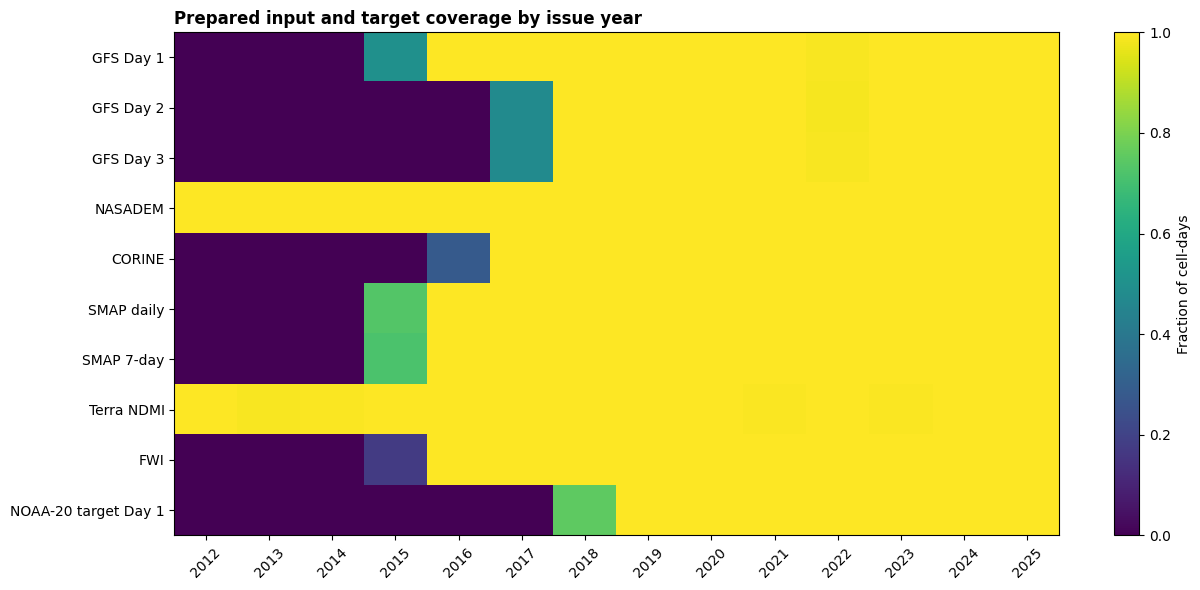

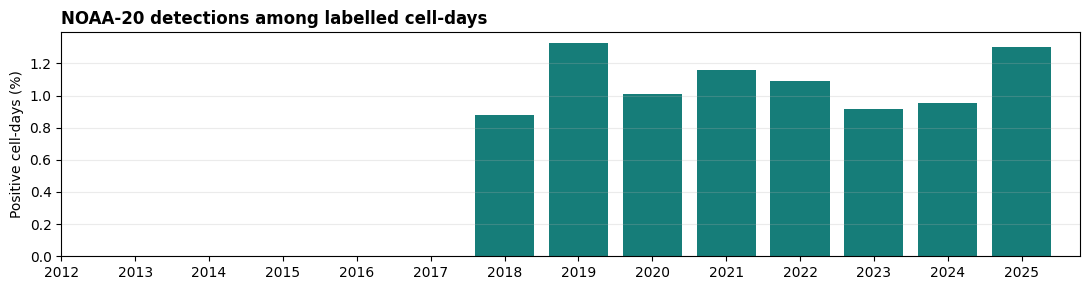

,labelled,positives,prevalence
issue_utc,,,
2012,0,0.0,NaN
2013,0,0.0,NaN
2014,0,0.0,NaN
2015,0,0.0,NaN
2016,0,0.0,NaN
2017,0,0.0,NaN
2018,79200,696.0,0.0088
2019,105120,1395.0,0.0133
2020,105408,1064.0,0.0101


In [5]:
panel = pd.concat([environment, targets], axis=1).reset_index()
del environment, targets
panel["lat_center"] = ((panel["cell_y"] + 0.5) * CELL_DEG).astype(np.float32)
panel["lon_center"] = ((panel["cell_x"] + 0.5) * CELL_DEG).astype(np.float32)
phase = 2 * np.pi * (panel["issue_utc"].dt.dayofyear - 1) / 365.25
panel["season_sin"] = np.sin(phase).astype(np.float32)
panel["season_cos"] = np.cos(phase).astype(np.float32)

COMMON = ["lat_center", "lon_center", "season_sin", "season_cos",
          *TERRAIN, *LAND, *SMAP, *NDMI, *FWI]
FEATURES = {day: [*COMMON, *(column for earlier in range(1, day + 1) for column in GFS[earlier])]
            for day in HORIZONS}

issue_year = panel["issue_utc"].dt.year
annual = {}
for group, columns in {
    "GFS Day 1": GFS[1], "GFS Day 2": GFS[2], "GFS Day 3": GFS[3],
    "NASADEM": TERRAIN, "CORINE": LAND, "SMAP daily": SMAP[:1], "SMAP 7-day": SMAP[1:],
    "Terra NDMI": NDMI, "FWI": FWI, "NOAA-20 target Day 1": ["target_day1"],
}.items():
    annual[group] = panel[columns].notna().all(axis=1).groupby(issue_year).mean()
annual_coverage = pd.DataFrame(annual).T

fig, ax = plt.subplots(figsize=(13, 6))
image = ax.imshow(annual_coverage, cmap="viridis", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(annual_coverage.columns)), annual_coverage.columns, rotation=45)
ax.set_yticks(range(len(annual_coverage.index)), annual_coverage.index)
ax.set_title("Prepared input and target coverage by issue year", loc="left", fontweight="bold")
fig.colorbar(image, ax=ax, label="Fraction of cell-days")
fig.tight_layout()
plt.show()

label_year = panel.groupby(issue_year)["target_day1"].agg(labelled="count", positives="sum", prevalence="mean")
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(label_year.index, 100 * label_year["prevalence"], color="#167d79")
ax.set(xticks=label_year.index, ylabel="Positive cell-days (%)")
ax.set_title("NOAA-20 detections among labelled cell-days", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(label_year.round(4))

In [6]:
SPLITS = {"train": (TRAIN_FROM, VALID_FROM), "validation": (VALID_FROM, TEST_FROM),
          "test": (TEST_FROM, STOP_UTC)}


def labelled_rows(day, split):
    start, stop = SPLITS[split]
    issue = panel["issue_utc"]
    verification_day = issue + pd.Timedelta(days=day - 1)
    return issue.ge(start) & verification_day.lt(stop) & panel[f"target_day{day}"].notna()


split_rows = {}
summaries = []
for day in HORIZONS:
    for split in SPLITS:
        rows = labelled_rows(day, split)
        split_rows[day, split] = rows
        labels = panel.loc[rows, f"target_day{day}"]
        summaries.append({"lead_day": day, "split": split, "cell_days": len(labels),
                          "positives": int(labels.sum()), "positive_rate": labels.mean(),
                          "first_issue_utc": panel.loc[rows, "issue_utc"].min()})
        if labels.nunique() != 2:
            raise ValueError(f"Day {day} {split} has {len(labels):,} labelled cell-days and "
                             f"{int(labels.sum()):,} positives. Check verified NOAA-20 coverage and split dates.")

split_summary = pd.DataFrame(summaries)
display(split_summary.round(5))

,lead_day,split,cell_days,positives,positive_rate,first_issue_utc
0,1,train,657504,6893,0.01048,2018-04-01 00:00:00+00:00
1,1,validation,52992,600,0.01132,2024-07-01 00:00:00+00:00
2,1,test,105120,1366,0.01299,2025-01-01 00:00:00+00:00
3,2,train,657504,6893,0.01048,2018-03-31 00:00:00+00:00
4,2,validation,52704,596,0.01131,2024-07-01 00:00:00+00:00
5,2,test,104832,1360,0.01297,2025-01-01 00:00:00+00:00
6,3,train,657504,6893,0.01048,2018-03-30 00:00:00+00:00
7,3,validation,52416,590,0.01126,2024-07-01 00:00:00+00:00
8,3,test,104544,1352,0.01293,2025-01-01 00:00:00+00:00


## Fit three CatBoost classifiers

Each model uses the same issue time and its own daily NOAA-20 label. Training uses unweighted binary log loss on the original class distribution. The initial score is the training positive rate. Validation log loss selects each model's tree count. A validation-only F1 threshold is used for thresholded test metrics. The probability columns retain the continuous model scores.

Run the temporal-feature cell below before fitting. It uses only the prepared inputs and past issue rows for trailing summaries. Windows with insufficient history stay missing.

In [7]:
# Build the environmental temporal predictors from the three-day experiment.
# Run after building the panel and before fitting CatBoost.
from pyarrow.parquet import ParquetFile


def build_temporal_features(panel):
    # Each matrix row is a UTC issue day. Each column is one fixed grid cell.
    if not pd.MultiIndex.from_frame(panel[KEYS]).equals(PANEL_INDEX):
        raise ValueError("Temporal features require the full, ordered daily grid.")

    n_cells = len(CELL_INDEX)
    values = {}

    def matrix(column):
        return pd.DataFrame(panel[column].to_numpy(dtype=np.float64).reshape(-1, n_cells))

    def add(column, daily_grid):
        values[column] = np.asarray(daily_grid, dtype=np.float32).ravel()

    # Historical weather summaries use Day 1 forecasts from past issues.
    # Shift first so today's target-day weather is outside these windows.
    for column, extreme in zip(GFS[1][:3], ("max", "min", "max")):
        previous = matrix(column).shift(1)
        for window, min_days in ((3, 2), (7, 5)):
            history = previous.rolling(window, min_periods=min_days)
            add(f"{column}_mean_prior_{window}d", history.mean())
            add(f"{column}_{extreme}_prior_{window}d", getattr(history, extreme)())

    previous_rain = matrix(GFS[1][-1]).shift(1)
    for window in (3, 7, 14):
        add(f"gfs_precip_sum_prior_{window}d", previous_rain.rolling(window).sum())

    previous_fwi = matrix("fwi").shift(1)
    add("fwi_mean_prior_7d", previous_fwi.rolling(7, min_periods=5).mean())

    for column, lag in (("smap_surface_daily", 7), ("ndmi_mean", 8)):
        series = matrix(column)
        add(f"{column}_change_{lag}d", series - series.shift(lag))

    # Observation age is available when the corresponding Drive export carries
    # the original observation or composite date. Missing dates stay NaN.
    for column, source_key, date_column in (
        ("smap_surface_daily", "/".join(SMAP), "smap_observation_day_utc"),
        ("ndmi_mean", NDMI[0], "ndmi_composite_start_utc"),
    ):
        path = Path(SOURCE_NOTES[source_key])
        if date_column not in ParquetFile(path).schema_arrow.names:
            continue
        dates = pd.read_parquet(path, columns=[*KEYS, date_column])
        dates = align_table(dates, KEYS, PANEL_INDEX, path)[date_column]
        age = (PANEL_INDEX.get_level_values("issue_utc") - utc(dates)).dt.days
        usable = panel[column].notna().to_numpy() & age.ge(0).to_numpy()
        add(f"{column}_age_days", age.where(usable))

    common_columns = list(values)
    by_lead = {}
    for day in HORIZONS:
        by_lead[day] = common_columns.copy()
        if day > 1:
            # Use the same GFS cycle already loaded for the daily forecasts.
            rain_columns = [GFS[earlier][-1] for earlier in range(1, day + 1)]
            column = f"gfs_rain_through_day{day}"
            add(column, panel[rain_columns].sum(axis=1, min_count=day))
            by_lead[day].append(column)

    return pd.DataFrame(values, index=panel.index, copy=False), by_lead


temporal_features, temporal_by_lead = build_temporal_features(panel)
# Make it safe to rerun this cell after a training interruption.
panel = pd.concat([panel.drop(columns=temporal_features.columns, errors="ignore"), temporal_features], axis=1)
del temporal_features
FEATURES = {day: list(dict.fromkeys([*FEATURES[day], *temporal_by_lead[day]])) for day in HORIZONS}

for day in HORIZONS:
    print(f"Day {day}: {len(temporal_by_lead[day])} temporal predictors, {len(FEATURES[day])} total.")

training_null = panel.loc[split_rows[3, "train"], FEATURES[3]].isna().all()
if training_null.any():
    print(f"Features fully missing in training: {training_null[training_null].index.tolist()}")

Day 1: 20 temporal predictors, 38 total.
Day 2: 21 temporal predictors, 43 total.
Day 3: 21 temporal predictors, 47 total.


In [8]:
CATBOOST_PARAMS = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.06,
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "boost_from_average": True,
    "nan_mode": "Min",
    "random_seed": SEED,
    "thread_count": CPU_THREADS,
    "task_type": "CPU",
    "allow_writing_files": False,
    "metric_period": 1,
}
EARLY_STOPPING = 50
models, histories, thresholds, validation_baselines = {}, {}, {}, {}

for day in HORIZONS:
    print(f"\nTraining Day {day}", flush=True)
    label = f"target_day{day}"
    inputs = FEATURES[day]
    train = split_rows[day, "train"]
    valid = split_rows[day, "validation"]
    y_train = panel.loc[train, label].astype(np.int8)
    y_valid = panel.loc[valid, label].astype(np.int8)
    x_valid = panel.loc[valid, inputs]

    model = CatBoostClassifier(**CATBOOST_PARAMS)
    model.fit(panel.loc[train, inputs], y_train, eval_set=(x_valid, y_valid),
              use_best_model=True, early_stopping_rounds=EARLY_STOPPING, verbose=100)
    models[day] = model
    evaluation = model.get_evals_result()
    history = pd.DataFrame({"train_log_loss": evaluation["learn"]["Logloss"],
                            "validation_log_loss": evaluation["validation"]["Logloss"]})
    histories[day] = history.assign(trees=np.arange(1, len(history) + 1), lead_day=day)
    validation_baselines[day] = log_loss(y_valid, np.full(len(y_valid), y_train.mean()), labels=[0, 1])

    val_score = model.predict_proba(x_valid)[:, 1]
    precision, recall, candidates = precision_recall_curve(y_valid, val_score)
    numerator = 2 * precision[:-1] * recall[:-1]
    denominator = precision[:-1] + recall[:-1]
    f1 = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)
    thresholds[day] = float(candidates[np.argmax(f1)])
    print(f"Day {day}: {model.tree_count_} trees, validation AP "
          f"{average_precision_score(y_valid, val_score):.4f}, F1 threshold {thresholds[day]:.4f}")


Training Day 1
0:	learn: 0.0569244	test: 0.0611942	best: 0.0611942 (0)	total: 290ms	remaining: 2m 24s
100:	learn: 0.0397377	test: 0.0503622	best: 0.0503622 (100)	total: 34s	remaining: 2m 14s
200:	learn: 0.0385406	test: 0.0502890	best: 0.0502853 (194)	total: 1m 4s	remaining: 1m 36s
300:	learn: 0.0377482	test: 0.0502691	best: 0.0502400 (273)	total: 1m 37s	remaining: 1m 4s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.05024000758
bestIteration = 273

Shrink model to first 274 iterations.
Day 1: 274 trees, validation AP 0.1373, F1 threshold 0.0601

Training Day 2
0:	learn: 0.0569762	test: 0.0611344	best: 0.0611344 (0)	total: 273ms	remaining: 2m 16s
100:	learn: 0.0396898	test: 0.0501517	best: 0.0501345 (98)	total: 33.8s	remaining: 2m 13s
200:	learn: 0.0385759	test: 0.0499989	best: 0.0499873 (187)	total: 1m 3s	remaining: 1m 34s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.04994738699
bestIteration = 211

Shrink model to first 212 iterations.
Day 

## Learning curves

Compare training and validation log loss after each boosting iteration. The dashed reference is validation log loss when every score equals the training positive rate. A dotted line marks the retained tree count. A continuing decrease on training with rising validation loss indicates overfitting.

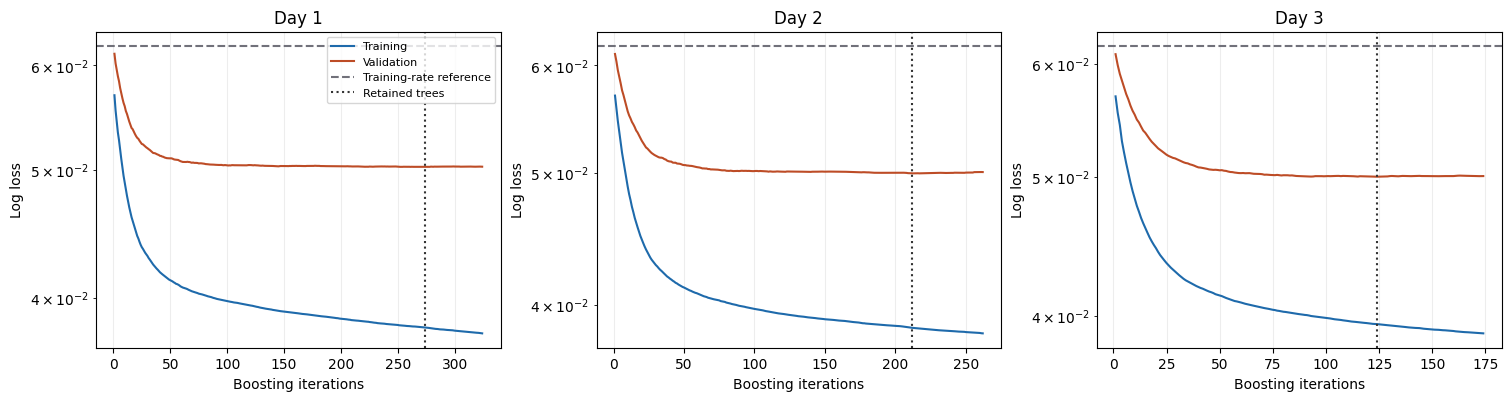

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), layout="constrained")
for day, ax in zip(HORIZONS, axes):
    history = histories[day]
    ax.plot(history["trees"], history["train_log_loss"], color="#1e6aab", label="Training")
    ax.plot(history["trees"], history["validation_log_loss"], color="#bd4c26", label="Validation")
    ax.axhline(validation_baselines[day], color="#71717a", linestyle="--", label="Training-rate reference")
    ax.axvline(models[day].tree_count_, color="#333333", linestyle=":", label="Retained trees")
    ax.set(title=f"Day {day}", xlabel="Boosting iterations", ylabel="Log loss", yscale="log")
    ax.grid(alpha=0.22)
axes[0].legend(loc="upper right", fontsize=8)
plt.show()

## Held-out forecasts and evaluation

Average precision (AP) measures the ranking of positive cells. Each precision-recall plot includes the observed test prevalence as a reference. Brier score and log loss measure probability error. Precision, recall and F1 use the fixed thresholds selected on validation. The maps show all three forecasts for one issue time on the same color scale.

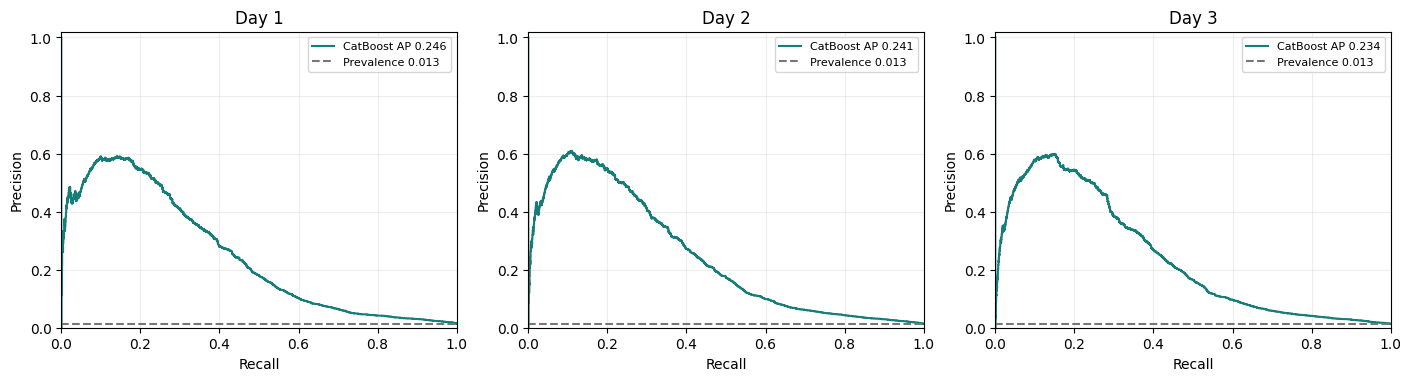

,lead_day,labelled_cell_days,positives,positive_rate,average_precision,log_loss,brier,threshold,precision,recall,f1
0,1,105120,1366,0.01299,0.24553,0.05106,0.01098,0.06009,0.30859,0.38653,0.34319
1,2,104832,1360,0.01297,0.24129,0.05131,0.01098,0.06730,0.31783,0.36176,0.33838
2,3,104544,1352,0.01293,0.23425,0.05164,0.01101,0.06138,0.31177,0.37426,0.34017


,issue_utc,cell_y,cell_x,lat_center,lon_center,valid_day1_utc,target_day1,p_day1,valid_day2_utc,target_day2,p_day2,valid_day3_utc,target_day3,p_day3
1367712,2025-01-01 00:00:00+00:00,152,-24,38.125,-5.875,2025-01-01 00:00:00+00:00,0,0.010976,2025-01-02 00:00:00+00:00,0,0.013946,2025-01-03 00:00:00+00:00,0,0.012282
1367713,2025-01-01 00:00:00+00:00,152,-23,38.125,-5.625,2025-01-01 00:00:00+00:00,0,0.012317,2025-01-02 00:00:00+00:00,0,0.016152,2025-01-03 00:00:00+00:00,0,0.010757
1367714,2025-01-01 00:00:00+00:00,152,-22,38.125,-5.375,2025-01-01 00:00:00+00:00,0,0.004431,2025-01-02 00:00:00+00:00,0,0.005626,2025-01-03 00:00:00+00:00,0,0.004477
1367715,2025-01-01 00:00:00+00:00,152,-21,38.125,-5.125,2025-01-01 00:00:00+00:00,0,0.005603,2025-01-02 00:00:00+00:00,0,0.008117,2025-01-03 00:00:00+00:00,0,0.007524
1367716,2025-01-01 00:00:00+00:00,152,-20,38.125,-4.875,2025-01-01 00:00:00+00:00,0,0.004710,2025-01-02 00:00:00+00:00,0,0.007378,2025-01-03 00:00:00+00:00,0,0.008885


In [10]:
test_issues = panel["issue_utc"].ge(TEST_FROM)
test_table = panel.loc[test_issues, [*KEYS, "lat_center", "lon_center"]].copy()
metrics = []
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), layout="constrained")

for day, ax in zip(HORIZONS, axes):
    target = f"target_day{day}"
    prob = f"p_day{day}"
    test_table[f"valid_day{day}_utc"] = test_table["issue_utc"] + pd.Timedelta(days=day - 1)
    test_table[target] = panel.loc[test_issues, target].astype("Int8")
    test_table[prob] = models[day].predict_proba(panel.loc[test_issues, FEATURES[day]])[:, 1]
    labelled = test_table[target].notna()
    y = test_table.loc[labelled, target].to_numpy(dtype=np.int8)
    score = test_table.loc[labelled, prob].to_numpy()
    flag = score >= thresholds[day]
    ap = average_precision_score(y, score)

    metrics.append({"lead_day": day, "labelled_cell_days": len(y), "positives": int(y.sum()),
                    "positive_rate": y.mean(), "average_precision": ap,
                    "log_loss": log_loss(y, score, labels=[0, 1]), "brier": brier_score_loss(y, score),
                    "threshold": thresholds[day], "precision": precision_score(y, flag, zero_division=0),
                    "recall": recall_score(y, flag, zero_division=0), "f1": f1_score(y, flag, zero_division=0)})
    precision, recall, _ = precision_recall_curve(y, score)
    ax.step(recall, precision, where="post", color="#167d79", label=f"CatBoost AP {ap:.3f}")
    ax.axhline(y.mean(), linestyle="--", color="#777777", label=f"Prevalence {y.mean():.3f}")
    ax.set(title=f"Day {day}", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.22)

plt.show()
test_metrics = pd.DataFrame(metrics)
display(test_metrics.round(5))
display(test_table.head())

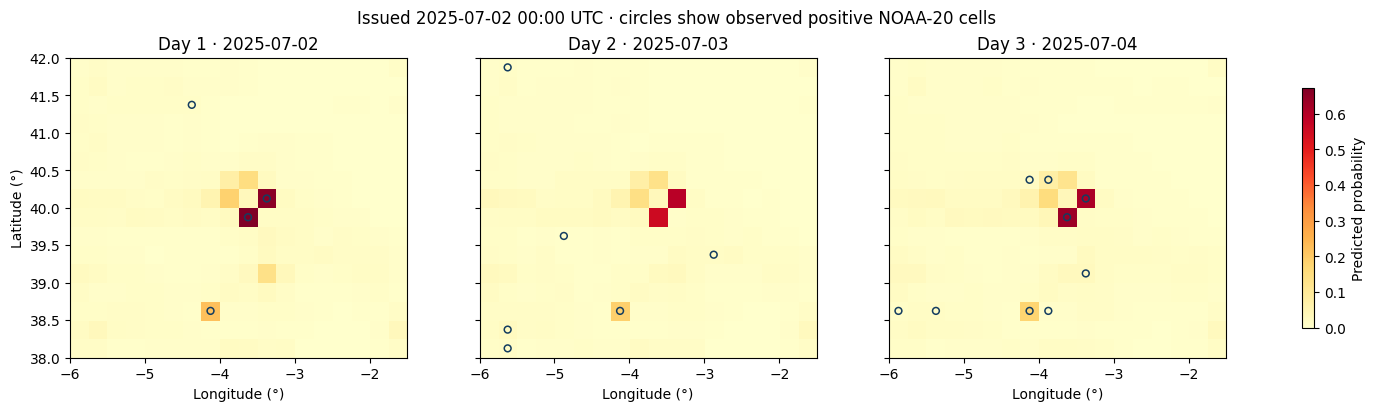

In [11]:
holdout_dates = pd.DatetimeIndex(test_table["issue_utc"].unique()).sort_values()
map_issue = pd.Timestamp(MAP_ISSUE_DATE, tz="UTC") if MAP_ISSUE_DATE else holdout_dates[len(holdout_dates) // 2]
map_frame = test_table.loc[test_table["issue_utc"].eq(map_issue)].sort_values(CELL_KEYS)
if len(map_frame) != len(CELL_INDEX):
    raise ValueError("Set MAP_ISSUE_DATE to a date in the holdout period.")

max_score = max(float(map_frame[f"p_day{day}"].max()) for day in HORIZONS)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True, layout="constrained")
for day, ax in zip(HORIZONS, axes):
    probability = map_frame[f"p_day{day}"].to_numpy().reshape(len(CELL_Y), len(CELL_X))
    image = ax.imshow(probability, origin="lower", extent=(WEST, EAST, SOUTH, NORTH),
                      cmap="YlOrRd", vmin=0, vmax=max(max_score, 0.001))
    positive = map_frame.loc[map_frame[f"target_day{day}"].eq(1).fillna(False)]
    ax.scatter(positive["lon_center"], positive["lat_center"], marker="o", s=24,
               facecolors="none", edgecolors="#143d60", linewidths=1.1)
    date = map_issue + pd.Timedelta(days=day - 1)
    ax.set(title=f"Day {day} · {date:%Y-%m-%d}", xlabel="Longitude (°)")
axes[0].set_ylabel("Latitude (°)")
fig.suptitle(f"Issued {map_issue:%Y-%m-%d %H:%M} UTC · circles show observed positive NOAA-20 cells")
fig.colorbar(image, ax=axes, label="Predicted probability", shrink=0.8)
plt.show()

## Save the trained models and three-day predictions

Each run writes to a new folder under `model_runs/noaa20_environment_catboost_3day/`. The prediction Parquet contains the issue time, grid keys, the three verification dates, probabilities and nullable observed labels. The run also includes the CatBoost models, test metrics, learning curves and feature order.

For inference, use the environmental features and their transformations in the exact order saved for each lead in `model_manifest.json`.

In [12]:
if SAVE_OUTPUTS:
    run_id = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S_%fZ")
    output_dir = DRIVE_ROOT / "model_runs" / "noaa20_environment_catboost_3day" / run_id
    output_dir.mkdir(parents=True)
    for day in HORIZONS:
        models[day].save_model(str(output_dir / f"catboost_day{day}.cbm"))
    test_table.reset_index(drop=True).to_parquet(output_dir / "three_day_test_predictions.parquet", index=False)
    test_metrics.to_csv(output_dir / "test_metrics.csv", index=False)
    pd.concat(histories.values(), ignore_index=True).to_csv(output_dir / "learning_curves.csv", index=False)

    manifest = {
        "target": {
            "platform": TARGET_PLATFORM,
            "source_products": list(TARGET_PRODUCTS),
            "observed_products": sorted(set(products_by_day) - {""}),
            "positive_rule": "at_least_one_detection_per_cell_verification_day",
            "uncovered_verification_days": "unlabelled",
        },
        "forecast_window_start_offsets_days": {day: day - 1 for day in HORIZONS},
        "bbox_wsen": [WEST, SOUTH, EAST, NORTH],
        "cell_degrees": CELL_DEG,
        "splits_utc_start_inclusive_end_exclusive": {
            name: [start.isoformat(), stop.isoformat()] for name, (start, stop) in SPLITS.items()
        },
        "firms_usage": "labels_only",
        "features_by_lead": FEATURES,
        "environmental_sources": SOURCE_NOTES,
        "corine_release_dates_used": CLC_RELEASE,
        "thresholds_chosen_on_validation": thresholds,
        "trees_by_lead": {day: models[day].tree_count_ for day in HORIZONS},
        "catboost_version": catboost.__version__,
        "catboost_parameters": CATBOOST_PARAMS,
    }
    (output_dir / "model_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Saved {len(test_table):,} three-day forecasts and model files to {output_dir}")

Saved 105,120 three-day forecasts and model files to /content/drive/MyDrive/spain_firms_2012_2025/model_runs/noaa20_environment_catboost_3day/20261115T161254_739462Z
